In [1]:
import arch.unitroot as ar
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import statsmodels.tsa.stattools as sms

In [2]:
N = 1000

In [3]:
eps = np.random.normal

In [4]:
y1 = np.zeros(N + 1)
y2 = np.zeros(N + 1)
y3 = np.zeros(N + 1)
y3b = np.zeros(N + 1)
for t in range(1, 1001):
    y1[t] = 0.5 * y1[t - 1] + eps()
    y2[t] = 10 + 0.5 * y2[t - 1] + eps()
    y3[t] = 10 + 0.2 * t + 0.5 * y3[t - 1] + eps()
    y3b[t] = 10 + 0.2 * t + (t >= 650) * 0.2 * (t - 650) + 0.5 * y3b[t - 1] + eps()

y1 = y1[500:800]
y2 = y2[500:800]
y3 = y3[500:800]
y3b = y3b[500:800]

# Простые тесты

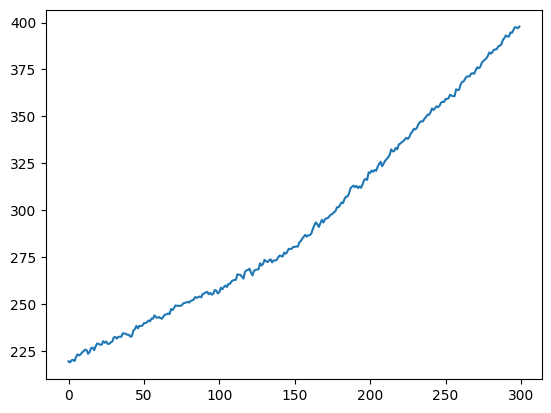

In [5]:
import matplotlib.pyplot as plt

f, (ax) = plt.subplots()
ax.plot(y3b)

In [ ]:
ar.ADF(y1, trend="n", method="bic")

In [ ]:
ar.ADF(y2, trend="c", method="bic")

In [ ]:
ar.ADF(y3, trend="ct", method="bic")

In [ ]:
sms.adfuller(y1, regression="n", autolag="BIC")

In [ ]:
ar.PhillipsPerron(y1, trend="n")

In [ ]:
ar.PhillipsPerron(y2, trend="c")

In [ ]:
ar.PhillipsPerron(y3, trend="ct")

In [ ]:
ar.KPSS(y1, trend="c")

In [ ]:
ar.KPSS(y2, trend="c")

In [ ]:
ar.KPSS(y3, trend="ct")

In [6]:
ar.ADF(y3b, trend="n", method="bic")

Test Statistic,11.793
P-value,1.000
Lags,2


In [7]:
ar.ADF(y3b, trend="c", method="bic")

Test Statistic,4.182
P-value,1.000
Lags,2


In [8]:
ar.ADF(y3b, trend="ct", method="bic")

Test Statistic,-0.675
P-value,0.975
Lags,2


In [9]:
ar.ADF(y3b, trend="ctt", method="bic")

Test Statistic,-2.657
P-value,0.479
Lags,2


In [10]:
ar.PhillipsPerron(y3b, trend="n")

Test Statistic,18.020
P-value,1.000
Lags,16


In [11]:
ar.PhillipsPerron(y3b, trend="c")

Test Statistic,5.400
P-value,1.000
Lags,16


In [12]:
ar.PhillipsPerron(y3b, trend="ct")

Test Statistic,-0.683
P-value,0.974
Lags,16


In [13]:
ar.KPSS(y3b, trend="c")

C:\Users\zyama\AppData\Local\Temp\ipykernel_15304\1543757127.py:1: DeprecationWarning: Lag selection has changed to use a data-dependent method. To use the old method that only depends on time, set lags=-1
  ar.KPSS(y3b, trend="c")


Test Statistic,2.774
P-value,0.000
Lags,10


In [14]:
ar.KPSS(y3b, trend="ct")

C:\Users\zyama\AppData\Local\Temp\ipykernel_15304\732427750.py:1: DeprecationWarning: Lag selection has changed to use a data-dependent method. To use the old method that only depends on time, set lags=-1
  ar.KPSS(y3b, trend="ct")


Test Statistic,0.707
P-value,0.000
Lags,10


In [18]:
ar.ZivotAndrews(y3b, trend="c")

Test Statistic,-2.329
P-value,0.991
Lags,6


In [19]:
res = ar.ZivotAndrews(y3b, trend="t")
res

Test Statistic,-6.120
P-value,0.003
Lags,6


In [20]:
(
    np.argmin(res._all_stats[~np.isnan(res._all_stats)])
    + sum(np.isnan(res._all_stats)) // 2
)

np.int64(148)

In [21]:
sms.zivot_andrews(y3b, regression="t")

(np.float64(-6.1196509696248365),
 np.float64(0.003287048717792622),
 {'1%': np.float64(-5.03421),
  '5%': np.float64(-4.4058),
  '10%': np.float64(-4.13678)},
 6,
 np.int64(148))

In [ ]:
y1x = np.zeros(N + 1)
y2x = np.zeros(N + 1)
y3x = np.zeros(N + 1)
y3bx = np.zeros(N + 1)
for t in range(1, 1001):
    y1x[t] = y1x[t - 1] + eps()
    y2x[t] = 10 + y2x[t - 1] + eps()
    y3x[t] = 10 + 0.2 * t + y3x[t - 1] + eps()

    y3bx[t] = 1 + (t >= 650) * 2 + y3bx[t - 1] + eps()

y1x = y1x[500:800]
y2x = y2x[500:800]
y3x = y3x[500:800]
y3bx = y3bx[500:800]

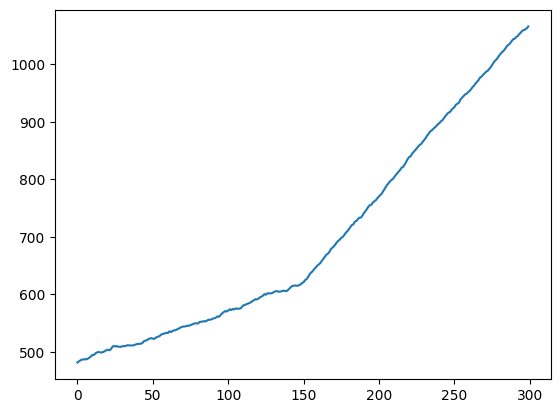

In [44]:
f, (ax) = plt.subplots()
ax.plot(y3bx)

In [31]:
ar.ADF(y3bx, trend="ct", method="bic")

Test Statistic,-1.630
P-value,0.780
Lags,0


In [ ]:
ar.ADF(y2x, trend="c", method="bic")

In [ ]:
ar.ADF(y3x, trend="ct", method="bic")

In [ ]:
ar.PhillipsPerron(y1x, trend="n")

In [ ]:
ar.PhillipsPerron(y2x, trend="c")

In [ ]:
ar.PhillipsPerron(y3x, trend="ct")

In [ ]:
ar.KPSS(y1x, trend="c")

In [ ]:
ar.KPSS(y2x, trend="c")

In [ ]:
ar.KPSS(y3x, trend="ct")

In [47]:
ar.ZivotAndrews(y3bx, trend="c")

Test Statistic,-3.437
P-value,0.719
Lags,14


In [48]:
sms.zivot_andrews(y3bx, regression="c")

(np.float64(-3.437053892435829),
 np.float64(0.7188972384631215),
 {'1%': np.float64(-5.27644),
  '5%': np.float64(-4.81067),
  '10%': np.float64(-4.56618)},
 14,
 np.int64(69))

## HEGY

In [ ]:
y4 = np.zeros(N + 4)
y5 = np.zeros(N + 4)
for t in range(1000):
    y4[t] = 0.5 * y4[t - 4] + eps()
    y5[t] = y5[t - 4] + eps()

y4 = y4[500:800]
y5 = y5[500:800]

In [ ]:
f, (ax) = plt.subplots()
ax.plot(y5)

In [ ]:
ar.ADF(y5, trend="n")

In [ ]:
f, (ax) = plt.subplots()
ax.plot(np.diff(y5))

In [ ]:
ar.ADF(np.diff(y5), trend="n")

In [ ]:
df = pd.DataFrame({"y": y4, "x": y5})

In [ ]:
df

In [ ]:
df["y1"] = df.y + df.y.shift(1) + df.y.shift(2) + df.y.shift(3)
df["x1"] = df.x + df.x.shift(1) + df.x.shift(2) + df.x.shift(3)

In [ ]:
df["y2"] = -(df.y - df.y.shift(1) + df.y.shift(2) - df.y.shift(3))
df["x2"] = -(df.x - df.x.shift(1) + df.x.shift(2) - df.x.shift(3))

In [ ]:
df["y3"] = -(df.y - df.y.shift(2))
df["x3"] = -(df.x - df.x.shift(2))

In [ ]:
df["y4"] = df.y - df.y.shift(4)
df["x4"] = df.x - df.x.shift(4)

In [ ]:
model = smf.ols(
    "y4 ~ -1 + y1.shift(1) + y2.shift(1) + y3.shift(2) + y3.shift(1)", data=df
).fit()
model.summary()

In [ ]:
model.t_test("y1.shift(1)")

In [ ]:
model.t_test("y2.shift(1)")

In [ ]:
model.f_test("y3.shift(2) = 0, y3.shift(1) = 0")

In [ ]:
model.f_test("y1.shift(1) = 0, y2.shift(1) = 0, y3.shift(2) = 0, y3.shift(1) = 0")

In [ ]:
model = smf.ols(
    "x4 ~ -1 + x1.shift(1) + x2.shift(1) + x3.shift(2) + x3.shift(1)", data=df
).fit()
model.summary()

In [ ]:
model.t_test("x1.shift(1)")

In [ ]:
model.t_test("x2.shift(1) = 0")

In [ ]:
model.f_test("x3.shift(2) = 0, x3.shift(1) = 0")

In [ ]:
model.f_test("x1.shift(1) = 0, x2.shift(1) = 0, x3.shift(2) = 0, x3.shift(1) = 0")

In [ ]:
ar.ADF(y5[4:] - y5[:-4])